# PC4

In [1]:
import os
import numpy as np
import xarray as xr
import rasterio
import rioxarray

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, FormatStrFormatter


# Configuración de GDAL para lectura remota (fijar antes de abrir cualquier archivo)
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"
os.environ["GDAL_HTTP_MERGE_CONSECUTIVE_RANGES"] = "YES"
os.environ["VSI_CACHE"] = "TRUE"

## Parte I
### Ejercicio 1

In [ ]:
# Cargar los datos
# import gdown
# gdown.download_folder(id="1ZP-yqBKVZ8bYkbnxJL_hQpxl0qz9MP-6", output="datos_proyecciones", quiet=False)

In [2]:
mb_2016 = rioxarray.open_rasterio("/home/sebas/GitHub/geocomp_1GE020/practicas/PC4/folder_PC4/mapbiomas_col4_2016_puerto_inca.tif").squeeze("band", drop=True)
mb_2025 = rioxarray.open_rasterio("/home/sebas/GitHub/geocomp_1GE020/practicas/PC4/folder_PC4/mapbiomas_col4_2025_puerto_inca.tif").squeeze("band", drop=True)

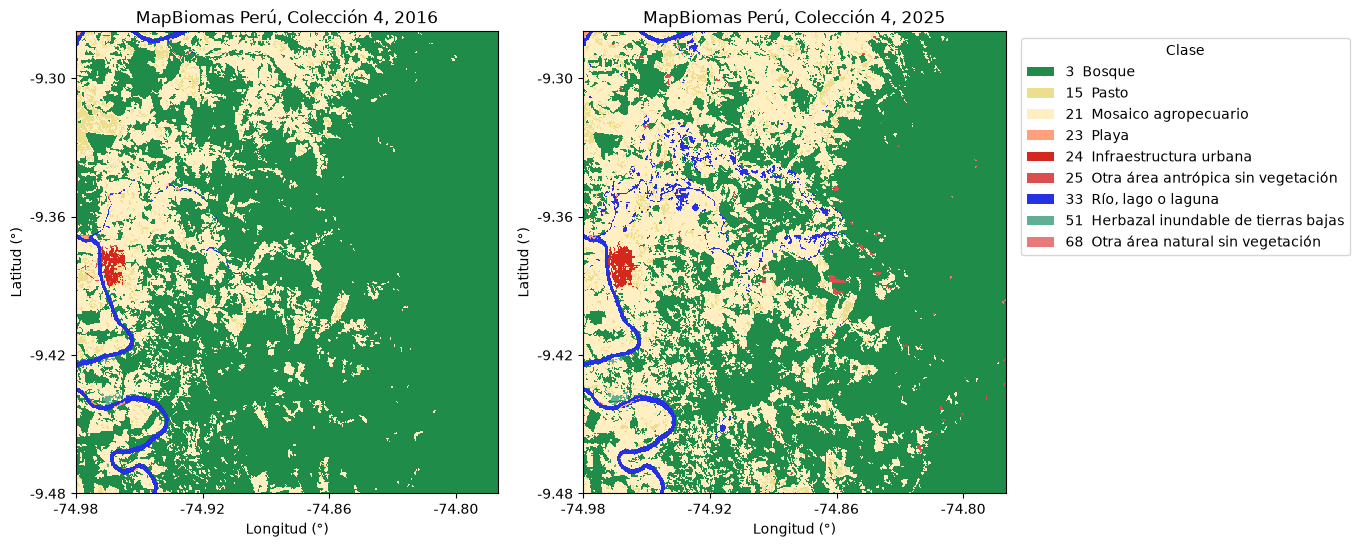

In [19]:
# Nombres y colores de las clases (ver la leyenda en las referencias)
LEYENDA = {
    3:  ("Bosque", "#1f8d49"), 
    6:  ("Bosque inundable", "#026975"), 
    15: ("Pasto", "#edde8e"), 
    21: ("Mosaico agropecuario", "#ffefc3"), 
    23: ("Playa", "#ffa07a"), 
    24: ("Infraestructura urbana", "#d4271e"), 
    25: ("Otra área antrópica sin vegetación", "#db4d4f"), 
    30: ("Minería", "#9c0027"), 
    33: ("Río, lago o laguna", "#2532e4"), 
    51: ("Herbazal inundable de tierras bajas", "#5faf92"), 
    66: ("Matorral y otros arbustales", "#a89358"), 
    68: ("Otra área natural sin vegetación", "#e97a7a"),
}

codigos = np.unique([mb_2016.values[~np.isnan(mb_2016.values)],mb_2016.values[~np.isnan(mb_2016.values)]]).astype(int) # Encuentra los códigos presentes e ignora los valores nulos
nombres = [LEYENDA.get(c, (f"Clase {c}", "#999999"))[0] for c in codigos] # extrae la lista de nombres y códigos de los presentes en la imagen.
colores = [LEYENDA.get(c, (f"Clase {c}", "#999999"))[1] for c in codigos]

idx_2016 = np.where(np.isnan(mb_2016.values), np.nan, np.searchsorted(codigos, mb_2016.values)) # Reindexa numéricamente las clases de la imagen
mb_idx_2016 = mb_2016.copy(data=idx_2016)
idx_2025 = np.where(np.isnan(mb_2025.values), np.nan, np.searchsorted(codigos, mb_2025.values)) # Reindexa numéricamente las clases de la imagen
mb_idx_2025 = mb_2025.copy(data=idx_2025)

fig, axes = plt.subplots(1,2,figsize=(12, 6))
mb_idx_2016.plot(
    ax=axes[0], cmap=ListedColormap(colores),
    vmin=-0.5, vmax=len(codigos) - 0.5, add_colorbar=False,
)
mb_idx_2025.plot(
    ax=axes[1], cmap=ListedColormap(colores),
    vmin=-0.5, vmax=len(codigos) - 0.5, add_colorbar=False,
)


axes[1].legend(
    handles=[Patch(facecolor=c, label=f"{k}  {n}") for k, n, c in zip(codigos, nombres, colores)],
    loc="upper left", bbox_to_anchor=(1.02, 1), title="Clase",
)
axes[0].set_title("MapBiomas Perú, Colección 4, 2016")
axes[0].set_xlabel("Longitud (°)")
axes[0].set_ylabel("Latitud (°)")

for eje in (axes[0].xaxis, axes[0].yaxis):
    eje.set_major_locator(MaxNLocator(4))
    eje.set_major_formatter(FormatStrFormatter("%.2f"))

axes[1].set_title("MapBiomas Perú, Colección 4, 2025")
axes[1].set_xlabel("Longitud (°)")
axes[1].set_ylabel("Latitud (°)")

for eje in (axes[1].xaxis, axes[1].yaxis):
    eje.set_major_locator(MaxNLocator(4))
    eje.set_major_formatter(FormatStrFormatter("%.2f"))

plt.savefig("Figura 1.png",dpi=300, bbox_inches="tight")
plt.show()

## Parte II
### Ejercicio 1

In [5]:
ndvi_2016 = rioxarray.open_rasterio("/home/sebas/GitHub/geocomp_1GE020/practicas/PC4/folder_PC4/ndvi_2016_puerto_inca.tif").squeeze("band", drop=True)
ndvi_2025 = rioxarray.open_rasterio("/home/sebas/GitHub/geocomp_1GE020/practicas/PC4/folder_PC4/ndvi_2025_puerto_inca.tif").squeeze("band", drop=True)

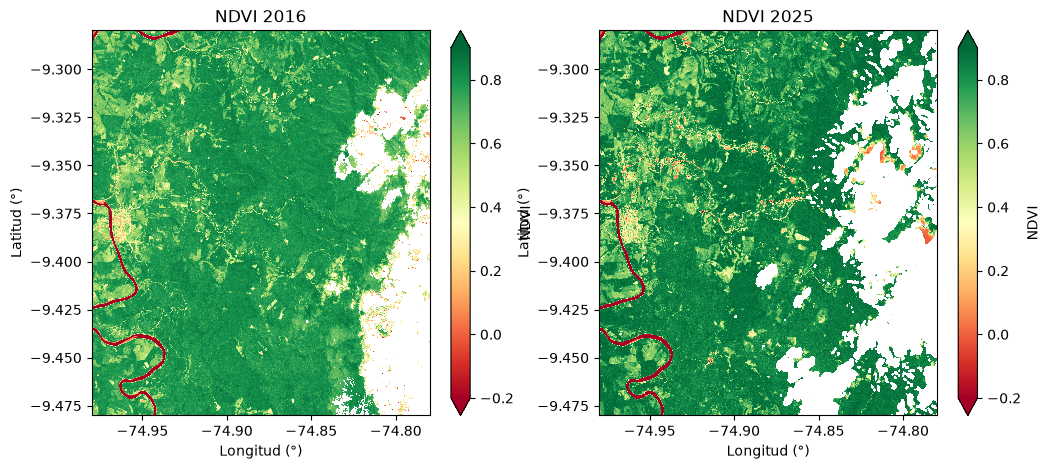

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Mapa con el transecto
ndvi_2016.plot(ax=axes[0], cmap="RdYlGn", vmin=-0.2, vmax=0.9, extend="both",
                     cbar_kwargs={"label": "NDVI"})
axes[0].set_title("NDVI 2016")
axes[0].set_xlabel("Longitud (°)")
axes[0].set_ylabel("Latitud (°)")

ndvi_2025.plot(ax=axes[1], cmap="RdYlGn", vmin=-0.2, vmax=0.9, extend="both",
                     cbar_kwargs={"label": "NDVI"})
axes[1].set_title("NDVI 2025")
axes[1].set_xlabel("Longitud (°)")
axes[1].set_ylabel("Latitud (°)")

plt.savefig("Figura 2.png",dpi=300, bbox_inches="tight")
plt.show()

Se puede evidenciar que el río aumenta en tonalidad con el pasar del tiempo, mientras que las zonas costeras han disminuido en área. Además, las porciones aisladas de tierra presentan costas una mayor área de roja en 2025 comparada a 2016. Asimismo, se evidencia la pérdida de vegetación en la zona sur central representada como la aparición de espacios blancos en el mapa. Se observa, a su vez, una disminución del NDVI en la parte superior izquierda, mientras que en el 2025, la parte central presenta una mayor tonalidad verde, indicando una mayor vegetación.

### Ejercicio 2

In [12]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import LineString

In [17]:
# Extracción del transecto (lon, lat), elegidos tras ver el mapa
P0, P1 = (-74.98, -9.38), (-74.90, -9.38)
n = 300
lons = np.linspace(P0[0], P1[0], n)
lats = np.linspace(P0[1], P1[1], n)

In [42]:
linea = gpd.GeoDataFrame(geometry=[LineString(zip(lons, lats))], crs="EPSG:4326")

# El buffer se hace en el CRS del NDVI (UTM) porque ahí la unidad es el metro
buffer500m = gpd.GeoDataFrame(geometry=linea.buffer(0.002), crs=ndvi_2016.rio.crs)

/tmp/ipykernel_23897/763330097.py:4: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  buffer500m = gpd.GeoDataFrame(geometry=linea.buffer(0.002), crs=ndvi_2016.rio.crs)


In [43]:
mb_c = mb_idx_2016.rio.clip(buffer500m.geometry, mb_2016.rio.crs, drop=True)

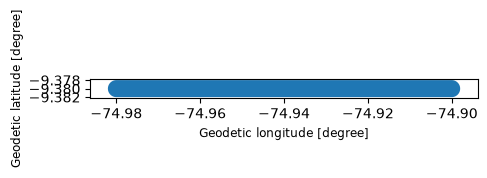

In [48]:
fig, ax = plt.subplots(figsize=(5,5))
buffer500m.plot(ax=ax)

plt.savefig("Figura 3.png",dpi=300, bbox_inches="tight")
plt.show()